# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
W, H, C, B = 1920, 1080, 3, 1            # width, height, channels, bytes per channel (8 bits)
MB, TB = 1024**2, 1024**4
N_CAMS, SECONDS_PER_DAY = 400, 24 * 60 * 60

# TODO 1: one 1080p RGB frame, in MB
frame_bytes = W * H * C * B              # 6,220,800 bytes
frame_mb = frame_bytes / MB

# TODO 2: frames per camera per day at 30 fps
frames_per_day = FPS * SECONDS_PER_DAY   # f x T

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = frame_bytes * frames_per_day * N_CAMS / TB

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
W_s, H_s, FPS_s = 640, 360, 10
fleet_tb_small = (W_s * H_s * C * B) * (FPS_s * SECONDS_PER_DAY) * N_CAMS / TB
pct_pixels_remaining = 100 * (W_s * H_s) / (W * H)

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")
print(f"Storage reduction factor: {fleet_tb / fleet_tb_small:.0f}x")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%
Storage reduction factor: 27x


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

- **Spatial — fine detail such as a licence plate or a face.** 640 × 360 keeps only about 11 % of the pixels. A
  plate that covered ~30 px in 1080p now covers ~10 px, so its characters fall below one pixel each. Upscaling later
  (bilinear/bicubic interpolation, Slide 13) only *estimates* the missing pixels from their neighbours; it cannot
  recover detail that was never stored, so the plate stays unreadable.
- **Temporal — fast, short events and the motion path between frames.** At 10 fps there is 100 ms between frames.
  A brief action (a hand throwing an object, the instant a window breaks, a muzzle flash) can fall entirely between
  two frames. A running person also moves much further between consecutive frames, so matching "the same object in
  the next frame" (the correspondence problem, Slides 36–37) becomes ambiguous and the exact trajectory is lost.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

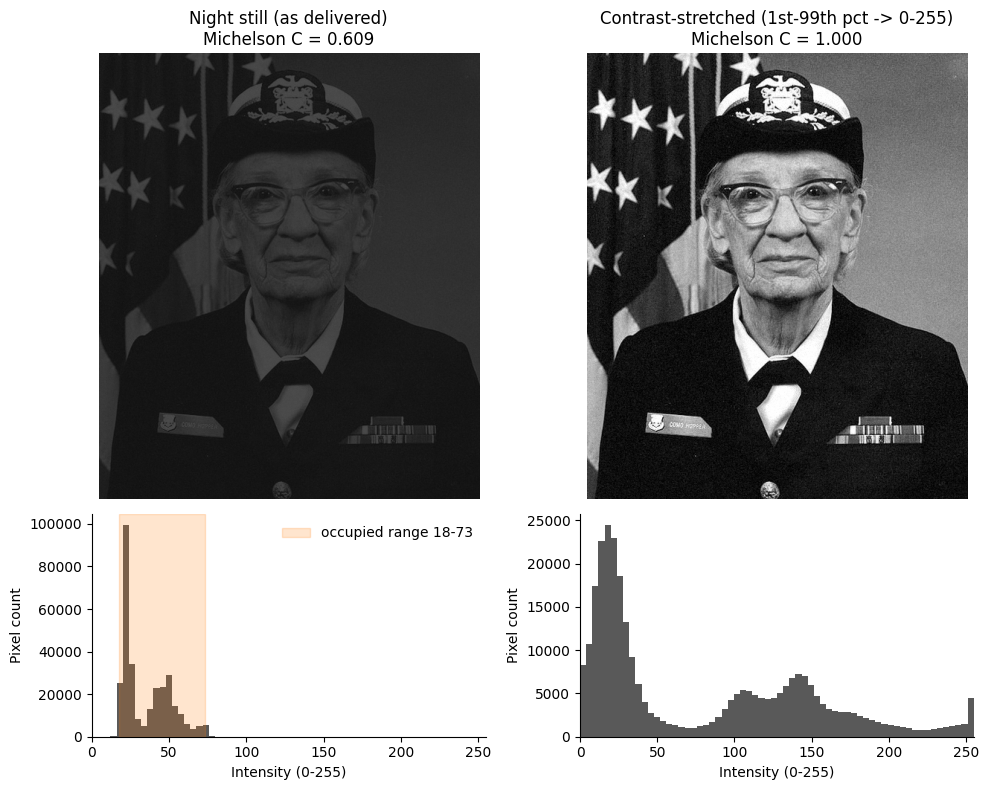

1st / 99th percentile before stretch: 17.8 / 73.4  (only 56 of 255 levels used)
Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

q1, q99 = np.percentile(stretched, [1, 99])
c_after = michelson(q99, q1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for col, (im, name, c) in enumerate([(night_still, "Night still (as delivered)", c_before),
                                     (stretched, "Contrast-stretched (1st-99th pct -> 0-255)", c_after)]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{name}\nMichelson C = {c:.3f}")
    axes[0, col].axis("off")
    axes[1, col].hist(im.ravel(), bins=64, range=(0, 255), color="0.35")
    axes[1, col].set_xlim(0, 255)
    axes[1, col].set_xlabel("Intensity (0-255)")
    axes[1, col].set_ylabel("Pixel count")
axes[1, 0].axvspan(p1, p99, color="tab:orange", alpha=0.2, label=f"occupied range {p1:.0f}-{p99:.0f}")
axes[1, 0].legend(frameon=False)

plt.tight_layout(); plt.show()
print(f"1st / 99th percentile before stretch: {p1:.1f} / {p99:.1f}  (only {p99 - p1:.0f} of 255 levels used)")
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").


The night histogram is **narrow and bunched toward the dark end**: almost every pixel sits between roughly 18 and
73, the whole range above ~80 is empty, and nothing is clipped at 0 or 255. In the Slide 18 vocabulary that is a
**dark (under-exposed), low-contrast** image — the problem is a compressed range, not clipping. The robust Michelson
contrast confirms it (≈ 0.61 before, 1.00 after).

Stretching is a monotonic remap of grey levels: every pixel keeps its rank, so it adds no new information — the
same edges and the same noise are still there. It helps because it spreads the ~56 occupied levels across the
full 0–255 range, so differences that were too small for the eye to see become large enough to notice.

A histogram only counts how many pixels have each intensity; it throws away *where* those pixels are. If you shuffled
every pixel of this image randomly, the histogram would be identical but the picture would be pure noise. So the
histogram tells us *how* the image is exposed, never *what* it shows.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing (< 3 px/s)   : first  68.70 s  ->  last  78.10 s   (24 raw run(s); short gaps are tracking jitter)
Running (> 25 px/s)   : first  78.60 s  ->  last  86.00 s   (1 raw run(s); short gaps are tracking jitter)
Loud sound   : frame 2250 (t = 75.00 s, -4.6 dB)
Lights jump  : frame 3000 (t = 100.00 s, brightness 62 -> 148)
Context      : car in view 20-32 s, person in view 40-86 s


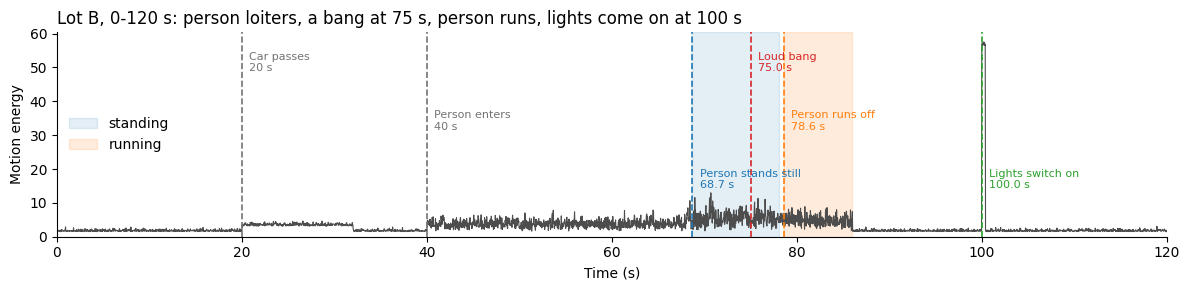

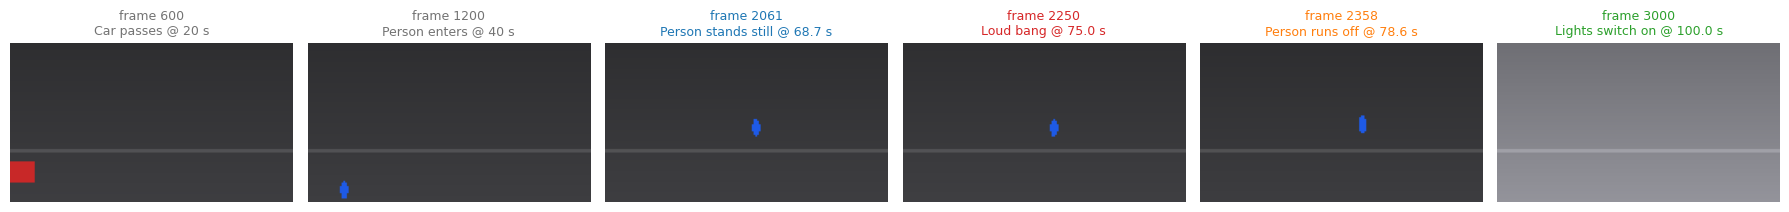

In [4]:
t = cctv["time_s"].to_numpy()

def ranges(mask, min_len=1):
    """Return contiguous (start_time, end_time) runs where mask is True."""
    idx = np.flatnonzero(mask)
    if idx.size == 0:
        return []
    runs = np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)
    return [(t[r[0]], t[r[-1]]) for r in runs if r.size >= min_len]

# TODO 1: person speed (px/s) -- displacement over 1 s (FPS frames) = px per second
dx = cctv["person_x"].diff(FPS)
dy = cctv["person_y"].diff(FPS)
speed = np.hypot(dx, dy)

# TODO 2: standing / running time ranges (print the first and last time of each)
standing = (speed < 3).to_numpy()
running = (speed > 25).to_numpy()
for name, m in [("Standing (< 3 px/s)", standing), ("Running (> 25 px/s)", running)]:
    print(f"{name:22s}: first {t[m].min():6.2f} s  ->  last {t[m].max():6.2f} s   "
          f"({len(ranges(m))} raw run(s); short gaps are tracking jitter)")
stand_start, stand_end = t[standing].min(), t[standing].max()
run_start, run_end = t[running].min(), t[running].max()

# TODO 3: event frame indices
audio_event_idx = int(np.flatnonzero(cctv["audio_level_db"].to_numpy() > -20)[0])
lighting_event_idx = int(np.flatnonzero(cctv["mean_brightness"].diff().to_numpy() > 40)[0])
stand_idx = int(np.flatnonzero(standing)[0])
run_idx = int(np.flatnonzero(running)[0])
car_idx = int(cctv["car_x"].first_valid_index())
person_idx = int(cctv["person_x"].first_valid_index())
print(f"Loud sound   : frame {audio_event_idx} (t = {t[audio_event_idx]:.2f} s, "
      f"{cctv['audio_level_db'].iloc[audio_event_idx]:.1f} dB)")
print(f"Lights jump  : frame {lighting_event_idx} (t = {t[lighting_event_idx]:.2f} s, "
      f"brightness {cctv['mean_brightness'].iloc[lighting_event_idx-1]:.0f} -> "
      f"{cctv['mean_brightness'].iloc[lighting_event_idx]:.0f})")
print(f"Context      : car in view {t[car_idx]:.0f}-{t[cctv['car_x'].last_valid_index()]:.0f} s, "
      f"person in view {t[person_idx]:.0f}-{t[cctv['person_x'].last_valid_index()]:.0f} s")

events = [  # (frame index, label, colour)
    (car_idx,            f"Car passes\n{t[car_idx]:.0f} s",                "0.45"),
    (person_idx,         f"Person enters\n{t[person_idx]:.0f} s",          "0.45"),
    (stand_idx,          f"Person stands still\n{t[stand_idx]:.1f} s",     "tab:blue"),
    (audio_event_idx,    f"Loud bang\n{t[audio_event_idx]:.1f} s",         "tab:red"),
    (run_idx,            f"Person runs off\n{t[run_idx]:.1f} s",           "tab:orange"),
    (lighting_event_idx, f"Lights switch on\n{t[lighting_event_idx]:.1f} s", "tab:green"),
]

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, cctv["motion_energy"], color="0.3", lw=0.8)
ax.axvspan(stand_start, stand_end, color="tab:blue", alpha=0.12, label="standing")
ax.axvspan(run_start, run_end, color="tab:orange", alpha=0.15, label="running")
ymax = cctv["motion_energy"].max()
for k, (i, lab, col) in enumerate(events):
    ax.axvline(t[i], color=col, ls="--", lw=1.2)
    ax.text(t[i] + 0.8, ymax * (0.95 - 0.3 * (k % 3)), lab, color=col, fontsize=8, va="top")
ax.set_xlim(0, 120); ax.set_ylim(0, ymax * 1.05)
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy")
ax.set_title("Lot B, 0-120 s: person loiters, a bang at 75 s, person runs, lights come on at 100 s", loc="left")
ax.legend(loc="center left", frameon=False)
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(3 * len(events), 2.6))
for ax, (i, lab, col) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i]))
    ax.set_title(f"frame {i}\n" + lab.replace("\n", " @ "), fontsize=9, color=col)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?


Uniform keyframes would be taken at 0, 20, 40, 60, 80 and 100 s. The **bang at 75.0 s** would almost certainly be
missed: it is above −20 dB for only about 0.4 s (75.0–75.37 s), and the picture at 75 s looks just like a person
standing still, so neither the 60 s nor the 80 s frame shows anything happening. The **start of the run (78.6 s)**
and the **start of standing (68.7 s)** would also be lost; the 80 s frame shows a person moving but not the
moment they started. The 100 s sample only catches the lighting change by luck, because it falls on exactly that
frame. Activity here is sparse and short, so fixed-interval sampling spends frames on empty parking lot and skips
the important moments. The approach I used is **content-based (event-driven) keyframe selection**: keyframes are
chosen where the content changes (motion vectors, audio level, brightness), not by the clock.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

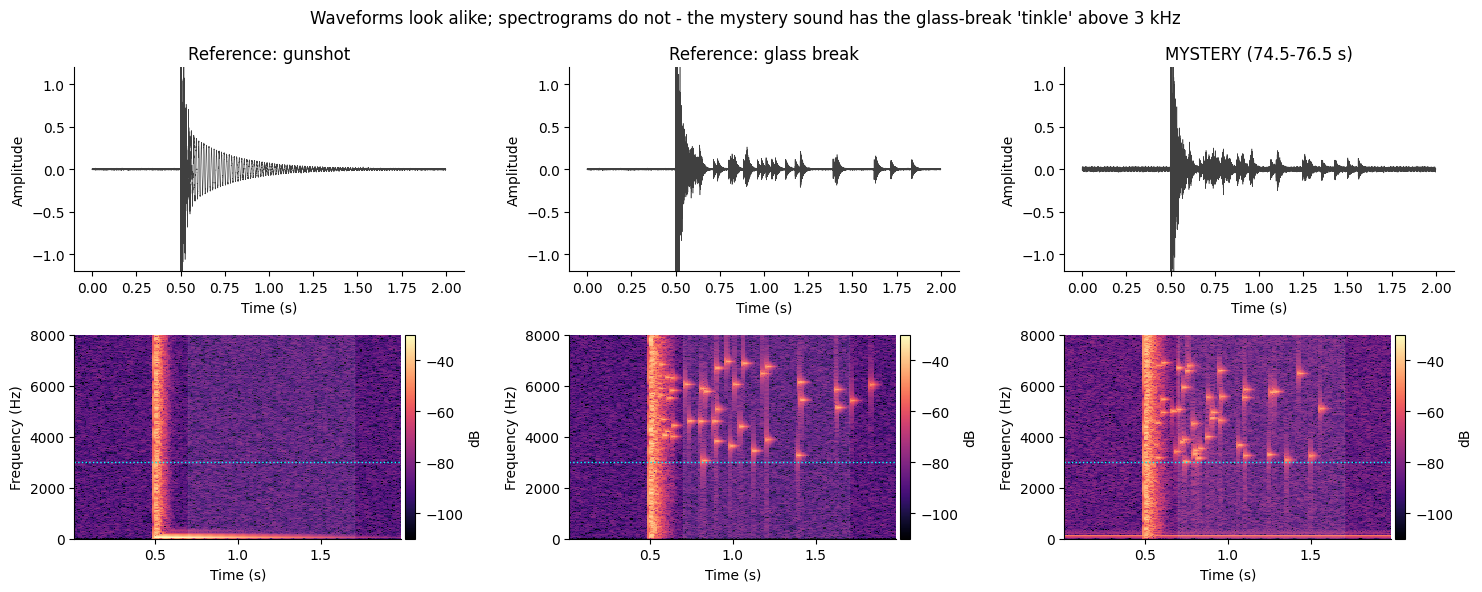

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
VERDICT: the 75 s sound is BREAKING GLASS - 87% of its post-impact energy is above 3 kHz (glass ref 99%, gunshot ref 0%).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
specs = {}
for col, (name, x) in enumerate(clips.items()):
    tt = np.arange(x.size) / FS
    axes[0, col].plot(tt, x, lw=0.4, color="0.25")
    axes[0, col].set_title(name)
    axes[0, col].set_xlabel("Time (s)"); axes[0, col].set_ylabel("Amplitude")
    axes[0, col].set_ylim(-1.2, 1.2)

    f, ts, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    specs[name] = (f, ts, Sxx)
    mesh = axes[1, col].pcolormesh(ts, f, 10 * np.log10(Sxx + 1e-12), shading="auto",
                                   cmap="magma", vmin=-110, vmax=-30)
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].axhline(3000, color="cyan", ls=":", lw=1)
    axes[1, col].axvspan(0.7, 1.7, color="white", alpha=0.08)
    axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Frequency (Hz)")
    fig.colorbar(mesh, ax=axes[1, col], label="dB", pad=0.01)
fig.suptitle("Waveforms look alike; spectrograms do not - the mystery sound has the glass-break 'tinkle' above 3 kHz")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, (f, ts, Sxx) in specs.items():
    win = (ts >= 0.5 + 0.2) & (ts <= 0.5 + 1.2)
    hf_fraction[name] = round(float(Sxx[f > 3000][:, win].sum() / Sxx[:, win].sum()), 3)

print(hf_fraction)
# TODO 4: verdict
ref_gun, ref_gls = hf_fraction["Reference: gunshot"], hf_fraction["Reference: glass break"]
m = hf_fraction["MYSTERY (74.5-76.5 s)"]
verdict = "BREAKING GLASS" if abs(m - ref_gls) < abs(m - ref_gun) else "GUNSHOT"
print(f"VERDICT: the 75 s sound is {verdict} - {m:.0%} of its post-impact energy is above 3 kHz "
      f"(glass ref {ref_gls:.0%}, gunshot ref {ref_gun:.0%}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?


Not confidently. All three start with the same sharp spike at 0.5 s. The gunshot has a smooth decaying tail,
while the glass break and the mystery clip have a few small bursts afterwards, but a waveform shows only
**amplitude over time**. It cannot tell us whether those bursts are high-pitched tinkles, low thuds or echoes, and
with real background noise they would be easy to miss. The waveform tells us *when* something loud happened, not
*what* made it.

The spectrogram adds **frequency**, giving three dimensions: **time** (x-axis) × **frequency** (y-axis) ×
**magnitude/energy** (colour). Both references start with a **vertical stripe** at 0.5 s, the broadband impact.
The gunshot then shows only a short **low-frequency horizontal band** (the ~70 Hz boom) and goes quiet above 3 kHz.
The glass break is followed by **scattered high-frequency specks** (3–7 kHz) for about a second as shards fall and
ring. The mystery clip has the same specks, and its high-frequency energy fraction matches the glass reference and
is far above the gunshot reference. **Verdict: breaking glass.**

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

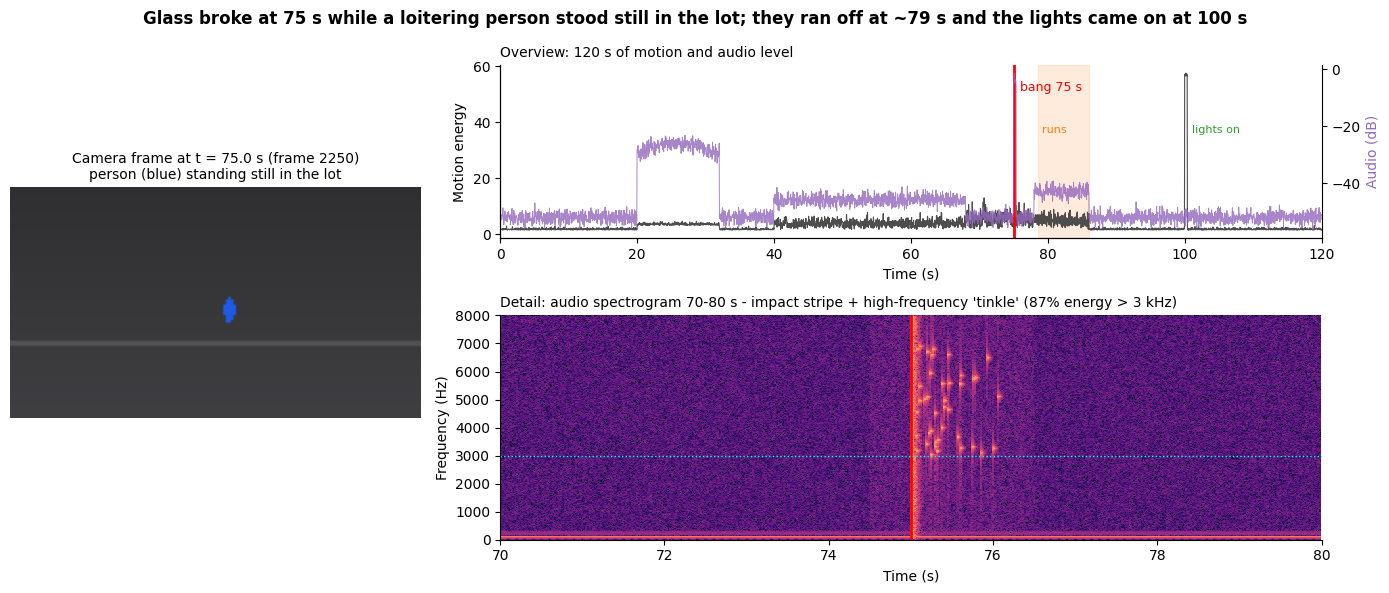

In [6]:
t_sel = 75.0
i_sel = int(np.argmin(np.abs(cctv["time_s"].to_numpy() - t_sel)))
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
# 1. Video frame at t_sel (left, spans both rows)
ax_img = fig.add_subplot(gs[:, 0])
ax_img.imshow(render_frame(cctv.iloc[i_sel]))
ax_img.set_title(f"Camera frame at t = {cctv['time_s'].iloc[i_sel]:.1f} s (frame {i_sel})\n"
                 "person (blue) standing still in the lot", fontsize=10)
ax_img.axis("off")

# 2. Overview: full 120 s motion + audio timeline
ax_tl = fig.add_subplot(gs[0, 1])
ax_tl.plot(cctv["time_s"], cctv["motion_energy"], color="0.3", lw=0.8, label="motion energy")
ax_tl.set_ylabel("Motion energy"); ax_tl.set_xlim(0, 120)
ax_au = ax_tl.twinx()
ax_au.spines["right"].set_visible(True)
ax_au.plot(cctv["time_s"], cctv["audio_level_db"], color="tab:purple", lw=0.7, alpha=0.8, label="audio level")
ax_au.set_ylabel("Audio (dB)", color="tab:purple")
ax_tl.axvline(t_sel, color="red", lw=2)
ax_tl.text(t_sel + 1, ax_tl.get_ylim()[1] * 0.85, "bang 75 s", color="red", fontsize=9)
ax_tl.axvspan(run_start, run_end, color="tab:orange", alpha=0.15)
ax_tl.text(run_start + 0.5, ax_tl.get_ylim()[1] * 0.6, "runs", color="tab:orange", fontsize=8)
ax_tl.text(t[lighting_event_idx] + 1, ax_tl.get_ylim()[1] * 0.6, "lights on", color="tab:green", fontsize=8)
ax_tl.set_title("Overview: 120 s of motion and audio level", loc="left", fontsize=10)
ax_tl.set_xlabel("Time (s)")

# 3. Detail: spectrogram of the 70-80 s audio
ax_sp = fig.add_subplot(gs[1, 1])
f, ts, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_sp.pcolormesh(ts + t_audio[0], f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-30)
ax_sp.axvline(t_sel, color="red", lw=2)
ax_sp.axhline(3000, color="cyan", ls=":", lw=1)
ax_sp.set_ylim(0, 8000); ax_sp.set_xlim(70, 80)
ax_sp.set_xlabel("Time (s)"); ax_sp.set_ylabel("Frequency (Hz)")
ax_sp.set_title("Detail: audio spectrogram 70-80 s - impact stripe + high-frequency 'tinkle' "
                f"({hf_fraction['MYSTERY (74.5-76.5 s)']:.0%} energy > 3 kHz)", loc="left", fontsize=10)

# 4. Conclusion-style title
fig.suptitle("Glass broke at 75 s while a loitering person stood still in the lot; they ran off at ~79 s "
             "and the lights came on at 100 s", fontsize=12, fontweight="bold")

plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

With a +2 s audio offset the bang would appear at **77 s** instead of 75 s, about 1.6 s before the person starts
running (78.6 s) rather than 3.6 s before. The cause-and-effect story would change. The video frame shown at the
"bang" would also be wrong, and someone could argue the person was already reacting or moving when the sound
happened, which changes who looks responsible. The **spectrogram panel** would show the mistake most clearly: its
vertical impact stripe would sit 2 s to the right of the red 75 s marker. The **overview timeline** would show it
too, because the audio-level spike would no longer line up with the marker. The figure is only useful as evidence if
every panel shares one clock, so the impact stripe, the audio spike and the red line must all coincide.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.


**To: Head of Security — Lot B incident, last night.**
A car passed through at 20–32 s; a person walked in at 40 s, stood still in the lot from about
68.7 s, and at **75.0 s glass broke** (not a gunshot). The person then **ran off at 78.6 s**, leaving the frame by
86 s, and the lot lights came on at 100 s. I would put the **synchronized one-screen view** first, because it
shows the whole chain from *structure → pattern → change → event → meaning* on a single clock: the timeline locates
the change, the camera frame shows who was there, and the spectrogram (time × frequency × magnitude) shows the
glass-break signature of high-frequency specks above 3 kHz, which a waveform alone cannot show. Uncompressed
1080p/30 fps across 400 cameras would be about **5,866 TB per day**, so I recommend a tiered policy: record
continuously at 640 × 360 / 10 fps (~217 TB/day before compression), and keep **full-resolution, full-frame-rate
clips for a window around every content-based event** (audio spike, sudden motion, lighting change). The one thing
that policy must not sacrifice is the **full-resolution frames around each event**, because that is where a face or
licence plate becomes readable, and interpolation cannot recover it later. The microphone audio must also stay at
its full 16 kHz sample rate, since the 3–7 kHz glass signature is what told us this was not a gunshot.